In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
from deepgar.paths import FIGURES_DIR, INTERIM_DATA_DIR, TABLES_DIR
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_probability as tfp
import tf_keras as keras
from tf_keras import layers
print(tf.__version__)
#import mlflow

2.7.0


In [3]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, root_mean_squared_error
import properscoring as ps
from scipy import optimize
from sstudentt import SST
from deepgar.models.deepgar_skew import QuantileLossModel, model_deepgar_skew_v2
from deepgar.plotting import loss_figure, train_dist_figure, test_dist_figure, get_cycle
from deepgar.sampling import sample_creation, created_naive_forecast, import_latest_data, import_data, invert_scale, invert_normalize

In [4]:
def rmse(y, f):
    assert y.shape[0] == f.shape[0]
    assert y.shape[0] > 0 and y.shape[0] is not None
    return np.sum(((y-f)**2))/y.shape[0]

def sum_neg_like(prob):
    return np.sum(np.log(prob))

In [5]:
def return_density(cond_quant):
    initial_estimates = np.array([1., 1., 1., 3.])

    parameters_est = optimize.leastsq(opt, initial_estimates, (cond_quant, ))

    #print(parameters_est)

    dist_result = SST( 
                  mu = parameters_est[0][0], 
                  sigma = parameters_est[0][1], 
                  nu = parameters_est[0][2],
                  tau = parameters_est[0][3]
                  )

    return dist_result, parameters_est

def opt(parameters, data):
    quantiles_config = [
             0.05,
             0.25,
             0.75,
             0.95]
    dist = SST(mu = parameters[0], sigma = parameters[1], nu = parameters[2], tau = parameters[3])
    error = dist.q(quantiles_config) - data
    return error

In [6]:
def denormalize_sigma(x, scaler):
    if scaler is None:
        result = x
    else:
        # Same units as denormalize(): percent. The original omitted the *100,
        # making the predictive spread 100x too narrow (see README).
        result = x*scaler['std'].iloc[0]*100
    return result

In [7]:
def generate_quantiles(num_quantiles):
    '''
    Create equally spaced quantiles
    '''
    return np.linspace(0.01, 0.99 , num_quantiles).tolist()

In [8]:
# Define the model parameters
param = {
    'NUM_FEATURES': 0,
    'NUM_QUANTILES': 2,
    'SPLIT': 0.75,
    'WINDOW_SIZE': 1,
    '1_COMMON_LSTM_NUM': 128,
    '2_COMMON_LSTM_NUM': 128,
    '1_IND_LSTM_NUM': 64,
    '1_IND_DENSE_NUM': 32,
    '1_IND_DENSE_ACTIVATION': 'relu',
    '1_OUT_DENSE_ACTIVATION': None,
    '1_LEARNING_RATE': 0.001,
    '2_SELECTION_METHOD': "weights", # "weights", "softmax_relu"
    '2_LSTM_NUM': 32,
    '2_DENSE_1_NUM': 16,
    '2_DENSE_1_ACTIVATION': None,
    '2_DENSE_2_ACTIVATION': 'tanh',
    '2_LEARNING_RATE': 0.001,
    'PRED_STEP': 1
}

EPOCHS1 = 95
EPOCHS2 = 2000

# Generate quantiles
#param['QUANTILES'] = generate_quantiles(param['NUM_QUANTILES'])
param['QUANTILES'] = [0.05, 0.25, 0.75, 0.95]

# EPOCHS
# Bulgaria   125
# Estonia    95
# Lithuania  150
# Romania    200


In [9]:
patience = int(EPOCHS1*0.10)
patience

9

In [10]:
scores = {'Country': [],
          'Model':[],
          'RMSE': [],
          'MAE': [],
          'CRPS': []}

In [11]:
country = "Bulgaria"

# Import and generate modeling sample
#dataset = import_latest_data()

data_file_dict = {
    'Bulgaria': 'data_Bulgaria_14.07.2022.csv',
    'Estonia': 'data_Estonia_14.07.2022.csv',
    'Lithuania': 'data_Lithuania_19.07.2022.csv',
    'Romania': 'data_Romania_14.04.2022_13.00.19.csv'
}

datafile = data_file_dict[country]
dataset = import_data(datafile)

# exclude risk factors

spec_dict = {
    'Bulgaria': ['GDP', 'SENTIMENT', 'SOFIX', 'US_BOND_YIELD'],
    'Estonia': ['GDP', 'SENTIMENT', 'OMXTGI_CLOSE'],
    'Lithuania': ['GDP', 'SENTIMENT', 'LT_BOND_YIELD'],
    'Romania': ['GDP', 'SENTIMENT', 'US_BOND_YIELD']
}

# subset predictors
dataset = dataset[spec_dict[country]]

data, scaler = sample_creation(dataset, param, prediction_step = param['PRED_STEP'])

naive = created_naive_forecast(data['TEST_DF'], param['WINDOW_SIZE'])
if isinstance(dataset, pd.DataFrame):
    param['NUM_FEATURES'] = data['TRAIN_DF'].shape[1]
else:
    param['NUM_FEATURES'] = 1

data/data_Bulgaria_14.07.2022.csv


In [12]:
len(dataset)*(param['SPLIT'])

54.75

In [13]:
param['NUM_FEATURES']

4

In [14]:
dataset.columns

Index(['GDP', 'SENTIMENT', 'SOFIX', 'US_BOND_YIELD'], dtype='object')

In [15]:
epochs_dict = {
    'Bulgaria': 125,
    'Estonia': 95,
    'Lithuania': 95,
    'Romania': 125,
}

In [16]:
import time
start = time.time()
# Estimate the models
y_train_dist, y_test_dist, history1, model1 = model_deepgar_skew_v2(param, data, epochs_dict[country], 50)
end = time.time()
print("Training took:" + str(round(end - start, 2)) + " sec")
model1.summary()

2023-07-26 13:23:11.008073: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


Epoch 1/125
1/2 [==============>...............] - ETA: 1s - loss: 2.9277
Loss_weights used: 0.95 0.05
2/2 [==============================] - 2s 359ms/step - loss: 2.9206 - val_loss: 3.4269
Epoch 2/125
1/2 [==============>...............] - ETA: 0s - loss: 2.7545
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.7320 - val_loss: 3.2940
Epoch 3/125
1/2 [==============>...............] - ETA: 0s - loss: 2.6156
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.6119 - val_loss: 3.1847
Epoch 4/125
1/2 [==============>...............] - ETA: 0s - loss: 2.5275
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.5052 - val_loss: 3.0780
Epoch 5/125
1/2 [==============>...............] - ETA: 0s - loss: 2.4004
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 2.4027 - val_loss: 2.9732
Epoch 6/125
1/2 [==============>...............] - ETA

1/2 [==============>...............] - ETA: 0s - loss: 0.5535
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.5492 - val_loss: 1.3872
Epoch 45/125
1/2 [==============>...............] - ETA: 0s - loss: 0.5454
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.5445 - val_loss: 1.3886
Epoch 46/125
1/2 [==============>...............] - ETA: 0s - loss: 0.5428
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.5394 - val_loss: 1.3878
Epoch 47/125
1/2 [==============>...............] - ETA: 0s - loss: 0.5380
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.5337 - val_loss: 1.3874
Epoch 48/125
1/2 [==============>...............] - ETA: 0s - loss: 0.5339
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.5299 - val_loss: 1.3948
Epoch 49/125
1/2 [==============>...............] - ETA: 0s - l

1/2 [==============>...............] - ETA: 0s - loss: 0.4177
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.4152 - val_loss: 1.2890
Epoch 88/125
1/2 [==============>...............] - ETA: 0s - loss: 0.4142
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.4121 - val_loss: 1.2880
Epoch 89/125
1/2 [==============>...............] - ETA: 0s - loss: 0.4130
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.4095 - val_loss: 1.2903
Epoch 90/125
1/2 [==============>...............] - ETA: 0s - loss: 0.4102
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 11ms/step - loss: 0.4061 - val_loss: 1.2952
Epoch 91/125
1/2 [==============>...............] - ETA: 0s - loss: 0.4065
Loss_weights used: 0.95 0.05
2/2 [==============================] - 0s 10ms/step - loss: 0.4031 - val_loss: 1.3011
Epoch 92/125
1/2 [==============>...............] - ETA: 0s - l

(<Figure size 720x432 with 1 Axes>,
 <AxesSubplot:title={'center':'Training and Validation Loss - Simultaneous Quantiles Generation & Crossing Loss'}, xlabel='Epochs', ylabel='Loss'>)

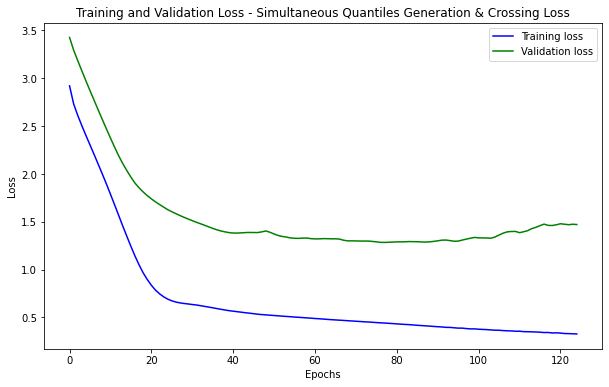

In [17]:
loss_figure(history1)

In [18]:
from tf_keras.utils import plot_model

# show_shapes=False: the TFP quantile ops produce tensors of unknown rank, which
# plot_model cannot label.
keras.utils.plot_model(model1, str(FIGURES_DIR / "1step_quantile_model.png"), show_shapes=False)

('You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) ', 'for plot_model/model_to_dot to work.')


In [19]:
yhat = model1([data['X_TEST'], data['Y_TEST']])
#yhat

In [20]:
m = yhat[0]#*scaler['std'].iloc[0] + scaler['mean'].iloc[0]
s = yhat[1]
a = yhat[2]
t = yhat[3]
#pd.DataFrame(np.array(tf.squeeze(m)))
#np.squeeze(np.array(m), axis=2).shape

In [21]:
pd_list = [pd.DataFrame(np.array(tf.squeeze(m)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(s)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(a)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.array(tf.squeeze(t)), index = data['TEST_DF'].index.to_list()[1:])]

final_df = (pd.concat(pd_list, axis=1))
final_df = final_df.set_axis(['LOC', 'STDEV', 'SKEWNESS', 'TAILWEIGHT'], axis=1)
final_df

,LOC,STDEV,SKEWNESS,TAILWEIGHT
2017Q3,0.061180,0.383554,-0.081534,1.582256
2017Q4,0.002117,0.424910,-0.138521,1.511063
2018Q1,-0.032141,0.467651,-0.098198,1.483986
2018Q2,-0.097434,0.425555,-0.214206,1.447096
2018Q3,-0.331721,0.443164,-0.276344,1.330685
2018Q4,-0.168797,0.507368,-0.206545,1.334809
2019Q1,-0.299072,0.479233,-0.219165,1.327335
2019Q2,2.563876,0.259753,0.339758,2.172987
2019Q3,-0.331300,0.451742,-0.110700,1.442947
2019Q4,-0.562484,0.432550,-0.173171,1.394203


In [22]:
def denormalize(x, scaler):
    return (x*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100

In [23]:
#from skewnormal_v2 import SkewNormal
#dist = SkewNormal(loc=list(np.squeeze(m)), scale=list(np.squeeze(s)), skewness=list(np.squeeze(a))
dist = tfp.distributions.SinhArcsinh(loc=np.float32(np.squeeze(m)), 
                                     scale=np.float32(np.squeeze(s)), 
                                     skewness=np.float32(np.squeeze(a)), 
                                     tailweight=np.float32(np.squeeze(t)))

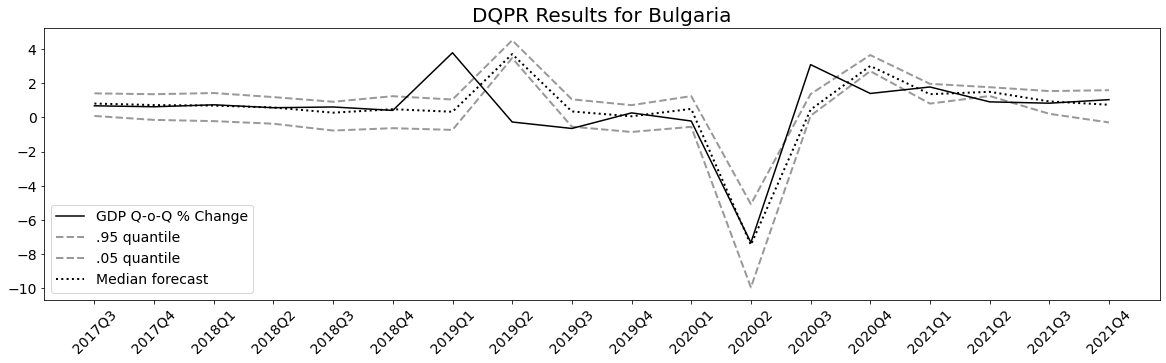

In [24]:
real_y = denormalize(data['Y_TEST'], scaler)
m = denormalize(m, scaler)
upper = denormalize(np.array(dist.quantile(0.95)), scaler)
lower = denormalize(np.array(dist.quantile(0.05)), scaler)
median = denormalize(np.array(dist.quantile(0.5)), scaler)

plt.figure(figsize=[20, 5])  # inches
#plt.style.use('grayscale')
plt.plot(real_y.squeeze(), label='GDP Q-o-Q % Change', color='black');
#plt.plot(m, 'r', linewidth=4, label='mean');
plt.plot(upper, linewidth=2, label=r'.95 quantile', linestyle="--", color='black', alpha=0.4);
plt.plot(lower, linewidth=2, label=r'.05 quantile', linestyle="--", color='black', alpha=0.4);
plt.plot(median, linewidth=2, label=r'Median forecast', linestyle="dotted", color='black');
#plt.plot((naive*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100, label="Naive Prediction", color='c');

ax=plt.gca();
ax.set_facecolor("white")
ax.set_xticks(range(len(data['TEST_DF'])-1))
ax.set_xticklabels(data['TEST_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.xticks(rotation = 45)
plt.legend(fontsize=14)
plt.title("DQPR Results for "+country, fontsize=20)
plt.savefig(str(FIGURES_DIR)+'/dqpr_'+country.lower()+'.png', bbox_inches='tight', facecolor="white")

In [25]:
yhat = model1([data['X_TEST'], data['Y_TEST']])
m = yhat[0]#*scaler['std'].iloc[0] + scaler['mean'].iloc[0]
s = yhat[1]
a = yhat[2]
t = yhat[3]

dist = tfp.distributions.SinhArcsinh(loc=np.float32(denormalize(np.squeeze(m), scaler)), 
                                     scale=np.float32(denormalize_sigma(np.squeeze(s), scaler)), 
                                     skewness=np.float32(np.squeeze(a)), 
                                     tailweight=np.float32(np.squeeze(t)))

samples = dist.sample(200)
descaled_mean = denormalize(m, scaler)

scores['Country'].append(country)
scores['Model'].append('DQPR')
scores['CRPS'].append(ps.crps_ensemble(real_y.squeeze(), np.array(samples).squeeze().T).mean())
#scores['RMSE'].append(root_mean_squared_error(real_y.squeeze(), descaled_mean))
scores['RMSE'].append(root_mean_squared_error(real_y.squeeze(), median.squeeze()))
scores['MAE'].append(mean_absolute_error(real_y.squeeze(), median.squeeze()))

In [26]:
scores

{'Country': ['Bulgaria'],
 'Model': ['DQPR'],
 'RMSE': [1.4828013076294697],
 'MAE': [0.8781652081099297],
 'CRPS': [1.0693090547904558]}

(array([5.55555547, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 4.44444338]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ],
       dtype=float32),
 <BarContainer object of 10 artists>)

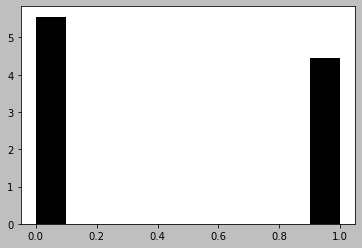

In [585]:
pit = pd.DataFrame(np.array(dist.cdf(real_y.squeeze())), index = data['TEST_DF'].index.to_list()[param['WINDOW_SIZE']:])

plt.hist(pit, 10, density=True)

In [586]:
real_y.min()

-5.8640365

In [587]:
median.min()

-5.603786

In [588]:
data['Y_TEST']

array([[ 8.27549239e-02],
       [ 1.73591854e-02],
       [-2.44187258e-03],
       [ 1.62318617e-01],
       [ 3.00023550e-03],
       [ 1.99208004e-01],
       [ 2.55201535e-01],
       [ 1.50900641e-01],
       [-2.17644250e-01],
       [ 2.02012256e-01],
       [-6.04784053e-02],
       [-3.16249779e+00],
       [ 1.42107094e+00],
       [ 3.26822268e-01],
       [ 3.98520979e-01],
       [ 1.60896150e-01],
       [-6.57521406e-02],
       [ 1.85165811e-01]])

In [589]:
dist_prob = pd.DataFrame(np.array(dist.prob(np.squeeze(real_y))), index = data['TEST_DF'].index.to_list()[1:])

dist_prob

,0
2017Q3,0.000000e+00
2017Q4,0.000000e+00
2018Q1,0.000000e+00
2018Q2,0.000000e+00
2018Q3,0.000000e+00
2018Q4,0.000000e+00
2019Q1,0.000000e+00
2019Q2,0.000000e+00
2019Q3,0.000000e+00
2019Q4,0.000000e+00


In [590]:
# Recession: q-o-q GDP growth below -0.1% (the original threshold of -0.001 as a growth rate).
# The original evaluated -0.001 in normalised units, i.e. P(growth < training-sample mean).
RECESSION_THRESHOLD = -0.1  # percent
recession = np.full(np.squeeze(real_y).shape, RECESSION_THRESHOLD, dtype=np.float32)
dist_cdf = pd.DataFrame(np.array(dist.cdf(list(recession))), index = data['TEST_DF'].index.to_list()[1:])
dist_cdf

,0
2017Q3,0.000000e+00
2017Q4,0.000000e+00
2018Q1,0.000000e+00
2018Q2,0.000000e+00
2018Q3,0.000000e+00
2018Q4,0.000000e+00
2019Q1,0.000000e+00
2019Q2,0.000000e+00
2019Q3,0.000000e+00
2019Q4,0.000000e+00


In [33]:
#country = datafile[datafile.find('/data_')+len('/data_'):datafile.rfind('_')]

In [35]:
pd_list = [pd.DataFrame(real_y.squeeze(), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(median, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(np.sqrt(np.power((real_y.squeeze()-median),2)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(lower, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(upper, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(upper-lower, index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(denormalize(np.squeeze(m), scaler)), index = data['TEST_DF'].index.to_list()[1:]), 
           pd.DataFrame(list(denormalize_sigma(np.squeeze(s), scaler)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(np.squeeze(a)), index = data['TEST_DF'].index.to_list()[1:]),
           pd.DataFrame(list(np.squeeze(t)), index = data['TEST_DF'].index.to_list()[1:]),
           dist_prob,
           dist_cdf]

final_df = (pd.concat(pd_list, axis=1))
final_df = final_df.set_axis(['GDP Actual', 
                   'Median',
                   'RMSE',
                   '.05 Quantile',
                   '.95 Quantile',
                   'IQR',
                   'Location', 
                   'Standard Deviation', 
                   'Skewness',
                   'Tailweight',
                   'Predictive Score', 
                   'Probability of recession'], axis=1)

#country = 'BG'

#final_df.to_csv('data/small_countries/'+'results_deepgar_'+country +'.csv')
#print("Exporting file to csv format at "+now.strftime('%d.%m.%Y_%H.%M.%S'))

(array([ 9., 15.,  9.,  9., 13.]),
 array([0.00197414, 0.19186981, 0.38176548, 0.5716612 , 0.7615568 ,
        0.9514525 ], dtype=float32),
 <BarContainer object of 5 artists>)

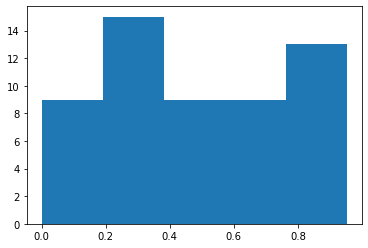

In [36]:
yhat_train = model1([data['X_TRAIN'], data['Y_TRAIN']])

m_train = yhat_train[0]
s_train = yhat_train[1]
a_train = yhat_train[2]
t_train = yhat_train[3]

dist_train = tfp.distributions.SinhArcsinh(loc=np.float32(np.squeeze(m_train)), 
                                     scale=np.float32(np.squeeze(s_train)), 
                                     skewness=np.float32(np.squeeze(a_train)), 
                                     tailweight=np.float32(np.squeeze(t_train)))

pit = pd.DataFrame(np.array(dist_train.cdf(np.squeeze(data['Y_TRAIN']))), index = data['TRAIN_DF'].index.to_list()[1:])

plt.hist(pit, 5)
#pit

In [37]:
denormalize(data['Y_TEST'], scaler)
#real_y

array([[ 1.036133 ],
       [ 0.8970863],
       [ 0.8549846],
       [ 1.2053041],
       [ 0.8665558],
       [ 1.2837396],
       [ 1.402795 ],
       [ 1.1810268],
       [ 0.3974138],
       [ 1.2897021],
       [ 0.7315853],
       [-5.8640365],
       [ 3.8817072],
       [ 1.5550775],
       [ 1.7075258],
       [ 1.2022796],
       [ 0.7203721],
       [ 1.2538826]])

In [38]:
print(rmse(real_y, np.squeeze(median)))

104.21731300479571


In [39]:
print(sum_neg_like(np.array(dist_prob)))

-15.024492


In [490]:
yhat = model1([data['X_TRAIN'], data['Y_TRAIN']])
#yhat

In [491]:
m = yhat[0]
s = yhat[1]
a = yhat[2]
t = yhat[3]
#pd.DataFrame(np.array(s))

In [42]:
dist = tfp.distributions.SinhArcsinh(loc=np.float32(np.squeeze(m)), scale=np.float32(np.squeeze(s)), skewness=np.float32(np.squeeze(a)), tailweight=np.float32(np.squeeze(t)))

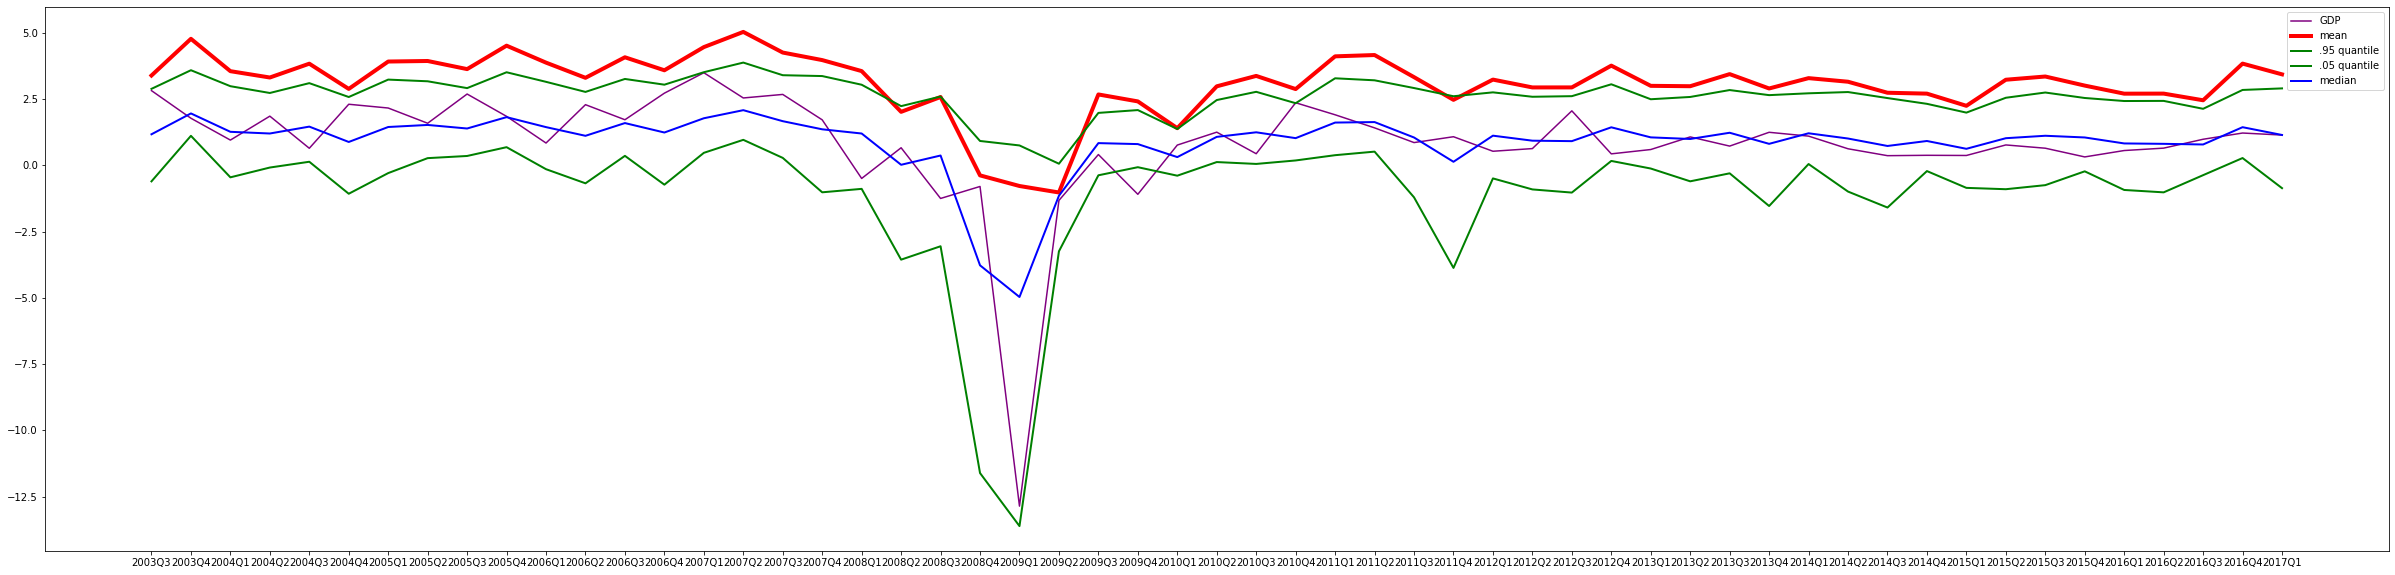

In [44]:
plt.figure(figsize=[42, 10])  # inches
real_y = (data['Y_TRAIN'].squeeze()*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100
m = (m*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100
plt.plot(real_y, label='GDP', color='purple');
plt.plot(m, 'r', linewidth=4, label='mean');
upper = (np.array(dist.quantile(0.95))*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100
lower = (np.array(dist.quantile(0.05))*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100
median = (np.array(dist.quantile(0.5))*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100

plt.plot(upper, 'g', linewidth=2, label=r'.95 quantile');
plt.plot(lower, 'g', linewidth=2, label=r'.05 quantile');
plt.plot(median, 'b', linewidth=2, label=r'median');


ax=plt.gca();
ax.set_xticks(range(len(data['TRAIN_DF'])-1))
ax.set_xticklabels(data['TRAIN_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
plt.legend()

#plt.savefig('charts/direct_density_estimation_train_set.png')

In [45]:
data['Y_TEST'].shape

(18, 1)

## AR1

In [621]:
#country = "Bulgaria"

# Import and generate modeling sample
#dataset = import_latest_data()

data_file_dict = {
    'Bulgaria': 'data_Bulgaria_14.07.2022.csv',
    'Estonia': 'data_Estonia_14.07.2022.csv',
    'Lithuania': 'data_Lithuania_19.07.2022.csv',
    'Romania': 'data_Romania_14.04.2022_13.00.19.csv'
}

datafile = data_file_dict[country]

dataset = import_data(datafile)

# exclude risk factors
#dataset = dataset.drop(['BRENT'], axis=1) # sufficient

# leave only gdp
dataset = dataset[['GDP']]

data, scaler = sample_creation(dataset, param, prediction_step = param['PRED_STEP'])

naive = created_naive_forecast(data['TEST_DF'], param['WINDOW_SIZE'])
if isinstance(dataset, pd.DataFrame):
    param['NUM_FEATURES'] = data['TRAIN_DF'].shape[1]
else:
    param['NUM_FEATURES'] = 1

data/data_Romania_14.04.2022_13.00.19.csv


In [622]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20)

def keras_pred(early_stop):
    # Set input_dim for the number of features.
    if len(data['X_TRAIN'].shape) == 1:
        input_dim = 1
    else:
        input_dim = data['X_TRAIN'].shape[0]
    model = keras.Sequential([
      keras.layers.Dense(1, activation='linear')
    ])
    
    model.compile(loss='mse', optimizer=keras.optimizers.Adam(0.001))
    model.fit(data['X_TRAIN'], data['Y_TRAIN'], epochs=200, batch_size=1,
              verbose=0, validation_split=0.2, callbacks=[early_stop])
    
    # Predict the quantile
    return model.predict(data['X_TEST']), model.predict(data['X_TRAIN']), model

In [623]:
forecast_test, forecast_train, ar_model = keras_pred(early_stop)

In [624]:
descaled_mean = denormalize(forecast_test, scaler)

stdev = np.std(data['Y_TRAIN'].squeeze()-forecast_train.squeeze())
stdev

0.6619229588416862

In [625]:
descaled_mean.shape

(21, 1, 1)

In [626]:
#descaled_mean

In [627]:
sigma_array = np.full(descaled_mean.squeeze().shape, stdev, dtype=np.float32)
sigma_array = denormalize_sigma(sigma_array, scaler)
sigma_array.squeeze().shape

(21,)

In [628]:
sigma_array[0]

0.01007066

In [629]:
dist = tfp.distributions.Normal(loc=descaled_mean.squeeze(), 
                                scale=sigma_array)

In [630]:
upper.shape

(21,)

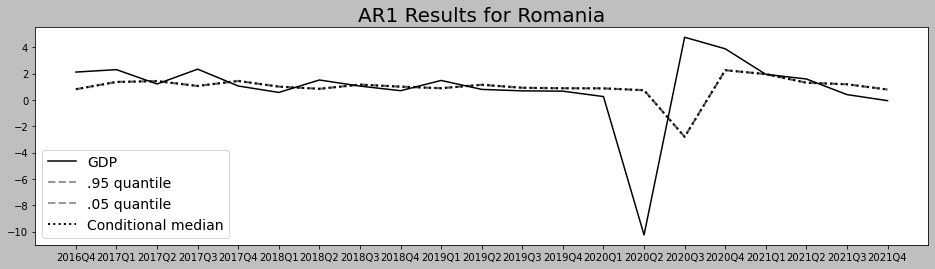

In [631]:
real_y = denormalize(data['Y_TEST'], scaler)
#m = denormalize(m, scaler)
upper = np.array(dist.quantile(0.95))
lower = np.array(dist.quantile(0.05))
median = np.array(dist.quantile(0.5))

plt.figure(figsize=[16, 4])  # inches

plt.plot(real_y.squeeze(), label='GDP', color='black');
#plt.plot(m, 'r', linewidth=4, label='mean');
plt.plot(upper, 'black', alpha=0.4, linewidth=2, label=r'.95 quantile', linestyle="--");
plt.plot(lower, 'black', alpha=0.4, linewidth=2, label=r'.05 quantile', linestyle="--");
plt.plot(median, 'black', linewidth=2, label=r'Conditional median', linestyle="dotted");
#plt.plot((naive*scaler['std'].iloc[0] + scaler['mean'].iloc[0])*100, label="Naive Prediction", color='c');

ax=plt.gca();
ax.set_xticks(range(len(data['TEST_DF'])-1))
ax.set_xticklabels(data['TEST_DF'].index.to_list()[1:])
#ax.xaxis.set_ticks_position('bottom')
#ax.yaxis.set_ticks_position('left')
#ax.spines['left'].set_position(('data', 0))
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['left'].set_smart_bounds(True)
#ax.spines['bottom'].set_smart_bounds(True)
plt.legend(fontsize=14)
plt.title("AR1 Results for "+country, fontsize=20)
plt.savefig(str(FIGURES_DIR)+'/ar1_'+country.lower()+'.png')


In [632]:
samples = dist.sample(200)

scores['Country'].append(country)
scores['Model'].append('AR1')
scores['CRPS'].append(ps.crps_ensemble(real_y.squeeze(), np.array(samples).squeeze().T).mean())
scores['RMSE'].append(root_mean_squared_error(real_y.squeeze(), descaled_mean.squeeze()))
scores['MAE'].append(mean_absolute_error(real_y.squeeze(), descaled_mean.squeeze()))

In [633]:
scores

{'Country': ['Bulgaria',
  'Bulgaria',
  'Estonia',
  'Estonia',
  'Lithuania',
  'Lithuania',
  'Romania',
  'Romania'],
 'Model': ['DQPR', 'AR1', 'DQPR', 'AR1', 'DQPR', 'AR1', 'DQPR', 'AR1'],
 'RMSE': [1.7030066545871687,
  2.3857458375625296,
  1.6374260532525144,
  1.9221107970887596,
  1.6184717535466195,
  2.2335855713965627,
  2.0735162046452107,
  2.9931552211950145],
 'MAE': [0.8781652081099297,
  1.2187877102637397,
  0.8066027991519384,
  1.1093505328567983,
  0.5047237263776991,
  1.0366811523848218,
  1.0263290769257072,
  1.417801056089649],
 'CRPS': [1.0693090547904558,
  1.2146202654336462,
  1.0181705462323656,
  1.1025808453371786,
  0.7648673481440621,
  1.0311213016239416,
  1.0648458406279342,
  1.412150752230681]}

In [634]:
pd.DataFrame.from_dict(scores)

,Country,Model,RMSE,MAE,CRPS
0,Bulgaria,DQPR,1.703007,0.878165,1.069309
1,Bulgaria,AR1,2.385746,1.218788,1.214620
2,Estonia,DQPR,1.637426,0.806603,1.018171
3,Estonia,AR1,1.922111,1.109351,1.102581
4,Lithuania,DQPR,1.618472,0.504724,0.764867
5,Lithuania,AR1,2.233586,1.036681,1.031121
6,Romania,DQPR,2.073516,1.026329,1.064846
7,Romania,AR1,2.993155,1.417801,1.412151


In [636]:
pd.DataFrame.from_dict(scores).to_csv(TABLES_DIR / "dqpr_ar1_summary.csv")